# abcopt Benchmark: ABC vs Random Search vs Optuna (TPE)

This notebook compares **abcopt** with two widely used baselines under an **identical evaluation budget**:

| Method | Implementation |
|---|---|
| **ABC** | `abcopt.CanonicalABCSolver` / `abcopt.ABCSearchCV` |
| **Random Search** | uniform sampling / `sklearn.model_selection.RandomizedSearchCV` |
| **Optuna TPE** | `optuna.samplers.TPESampler` with default settings |

Two settings are tested:

1. **Black-box functions:** four classic 10-dimensional test functions, 1,000 evaluations, 10 seeds.
2. **Hyperparameter tuning:** two scikit-learn tasks, 50 candidates (each one a 3-fold CV), 5 seeds, plus a held-out test set.

Every method gets the same budget, the same search space and, for tuning, the same CV splits, so the differences come from the search strategy alone.

In [1]:
# !pip install abcopt optuna matplotlib pandas
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import sklearn
from scipy.stats import loguniform, randint, uniform

import abcopt
from abcopt import ABCSearchCV, CanonicalABCSolver

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=UserWarning)

print(f"abcopt {abcopt.__version__} | optuna {optuna.__version__} | scikit-learn {sklearn.__version__}")

COLORS = {"ABC": "#d62728", "Random Search": "#7f7f7f", "Optuna TPE": "#1f77b4"}
METHODS = list(COLORS)

abcopt 0.2.0 | optuna 5.0.0 | scikit-learn 1.9.1


## Part 1: Black-box test functions

All functions are minimized in **D = 10** dimensions; the global minimum of each is **0**.

| Function | Domain | Character |
|---|---|---|
| Sphere | [-5.12, 5.12] | unimodal, separable (easy) |
| Rosenbrock | [-5, 10] | narrow curved valley |
| Rastrigin | [-5.12, 5.12] | highly multimodal, regular |
| Ackley | [-32.768, 32.768] | multimodal, flat outer region |

In [2]:
D = 10
BUDGET = 1000
SEEDS = range(10)

def sphere(x):
    return float(np.sum(x ** 2))

def rosenbrock(x):
    return float(np.sum(100 * (x[1:] - x[:-1] ** 2) ** 2 + (1 - x[:-1]) ** 2))

def rastrigin(x):
    return float(10 * len(x) + np.sum(x ** 2 - 10 * np.cos(2 * np.pi * x)))

def ackley(x):
    n = len(x)
    return float(-20 * np.exp(-0.2 * np.sqrt(np.sum(x ** 2) / n))
                 - np.exp(np.sum(np.cos(2 * np.pi * x)) / n) + 20 + np.e)

FUNCTIONS = {
    "Sphere": (sphere, -5.12, 5.12),
    "Rosenbrock": (rosenbrock, -5.0, 10.0),
    "Rastrigin": (rastrigin, -5.12, 5.12),
    "Ackley": (ackley, -32.768, 32.768),
}

In [3]:
def best_so_far(values):
    return np.minimum.accumulate(np.asarray(values, dtype=float))

def run_abc(f, lo, hi, seed):
    trace = []
    def obj(x):
        v = f(x)
        trace.append(v)
        return v
    CanonicalABCSolver(obj, D, [lo] * D, [hi] * D, pop_size=20,
                       max_evals=BUDGET, random_state=seed).solve()
    return best_so_far(trace)

def run_random(f, lo, hi, seed):
    rng = np.random.default_rng(seed)
    return best_so_far([f(rng.uniform(lo, hi, D)) for _ in range(BUDGET)])

def run_tpe(f, lo, hi, seed):
    study = optuna.create_study(sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(lambda t: f(np.array([t.suggest_float(f"x{i}", lo, hi) for i in range(D)])),
                   n_trials=BUDGET)
    return best_so_far([t.value for t in study.trials])

RUNNERS = {"ABC": run_abc, "Random Search": run_random, "Optuna TPE": run_tpe}

curves = {}   # (function, method) -> array (seeds x budget)
timing = {}
for fname, (f, lo, hi) in FUNCTIONS.items():
    for method, runner in RUNNERS.items():
        t0 = time.perf_counter()
        curves[fname, method] = np.array([runner(f, lo, hi, s) for s in SEEDS])
        timing[fname, method] = (time.perf_counter() - t0) / len(SEEDS)
    print(f"{fname:<11} done")

Sphere      done


Rosenbrock  done


Rastrigin   done


Ackley      done


In [4]:
rows = []
for (fname, method), c in curves.items():
    final = c[:, -1]
    rows.append({"Function": fname, "Method": method,
                 "mean": final.mean(), "std": final.std(), "median": np.median(final),
                 "best": final.min(), "sec/run": timing[fname, method]})
func_results = pd.DataFrame(rows)

table = func_results.pivot(index="Function", columns="Method", values="mean")[METHODS]
std = func_results.pivot(index="Function", columns="Method", values="std")[METHODS]
pretty = table.copy().astype(object)
for fn in table.index:
    winner = table.loc[fn].idxmin()
    for m in METHODS:
        cell = f"{table.loc[fn, m]:.3g} ± {std.loc[fn, m]:.2g}"
        pretty.loc[fn, m] = f"**{cell}**" if m == winner else cell
pretty = pretty.loc[list(FUNCTIONS)]
print(f"Best value after {BUDGET} evaluations (mean ± std over {len(SEEDS)} seeds, lower is better)\n")
print(pretty.to_markdown())

Best value after 1000 evaluations (mean ± std over 10 seeds, lower is better)

| Function   | ABC            | Random Search     | Optuna TPE      |
|:-----------|:---------------|:------------------|:----------------|
| Sphere     | 1.07 ± 0.92    | 20 ± 4.3          | **0.273 ± 0.1** |
| Rosenbrock | 374 ± 8.7e+02  | 3.3e+04 ± 1.8e+04 | **88.5 ± 38**   |
| Rastrigin  | **26.3 ± 6.7** | 85.6 ± 6.5        | 59.7 ± 6.1      |
| Ackley     | 12.6 ± 2       | 18.2 ± 0.71       | **5.58 ± 0.44** |


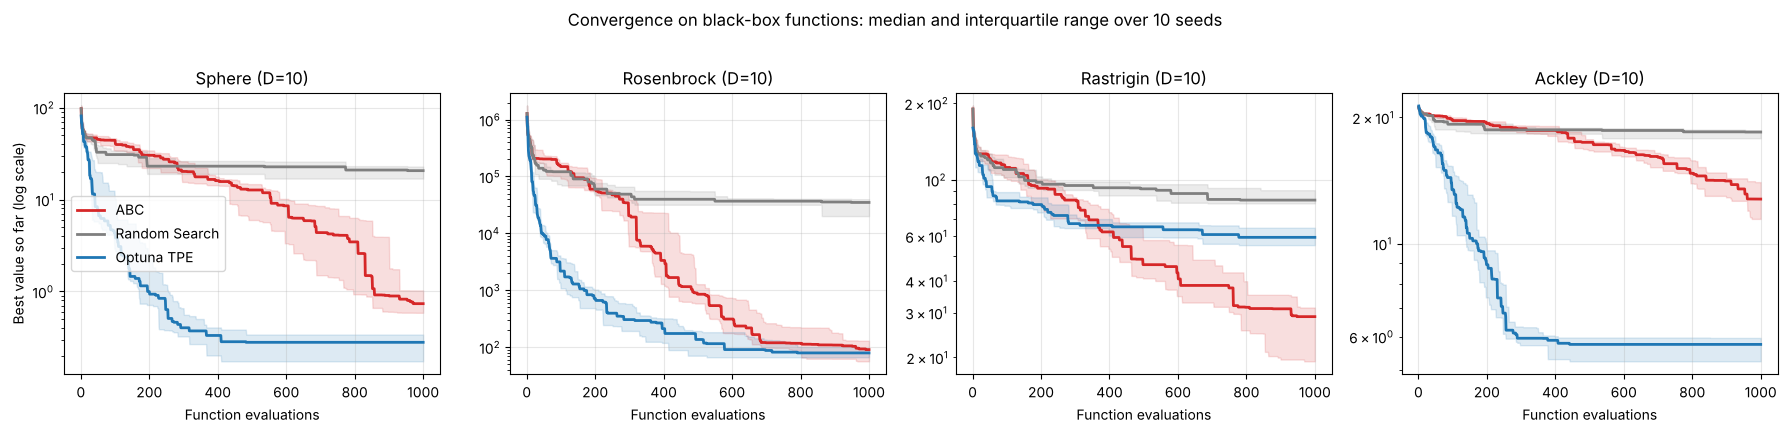

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
x = np.arange(1, BUDGET + 1)
for ax, fname in zip(axes, FUNCTIONS):
    for method in METHODS:
        c = curves[fname, method]
        med = np.median(c, axis=0)
        q1, q3 = np.percentile(c, [25, 75], axis=0)
        ax.plot(x, med, label=method, color=COLORS[method], lw=2)
        ax.fill_between(x, q1, q3, color=COLORS[method], alpha=0.15)
    ax.set_yscale("log")
    ax.set_title(f"{fname} (D={D})")
    ax.set_xlabel("Function evaluations")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Best value so far (log scale)")
axes[0].legend()
fig.suptitle("Convergence on black-box functions: median and interquartile range over 10 seeds", y=1.02)
fig.tight_layout()
fig.savefig("benchmark_functions.png", dpi=150, bbox_inches="tight")
plt.show()

### Part 1b: A longer budget

With 1,000 evaluations ABC is still clearly improving at the end of every curve, while TPE has flattened out. To see what happens next, ABC and Random Search are run for **10,000 evaluations** (10 seeds).

TPE is run only up to **2,000 evaluations with 3 seeds**: its own computation grows much faster than linearly with the number of trials (see the overhead table below), and 10,000 trials would take roughly 15 minutes per run on this machine.

In [6]:
LONG_BUDGET = 10_000
TPE_LONG = 2_000

def run_abc_long(f, lo, hi, seed, budget):
    trace = []
    def obj(x):
        v = f(x); trace.append(v); return v
    CanonicalABCSolver(obj, D, [lo] * D, [hi] * D, pop_size=20,
                       max_evals=budget, random_state=seed).solve()
    return best_so_far(trace)

def run_random_long(f, lo, hi, seed, budget):
    rng = np.random.default_rng(seed)
    return best_so_far([f(x) for x in rng.uniform(lo, hi, (budget, D))])

def run_tpe_long(f, lo, hi, seed, budget):
    study = optuna.create_study(sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(lambda t: f(np.array([t.suggest_float(f"x{i}", lo, hi) for i in range(D)])),
                   n_trials=budget)
    return best_so_far([t.value for t in study.trials])

long_curves = {}
for fname, (f, lo, hi) in FUNCTIONS.items():
    long_curves[fname, "ABC"] = np.array([run_abc_long(f, lo, hi, s, LONG_BUDGET) for s in SEEDS])
    long_curves[fname, "Random Search"] = np.array([run_random_long(f, lo, hi, s, LONG_BUDGET) for s in SEEDS])
    long_curves[fname, "Optuna TPE"] = np.array([run_tpe_long(f, lo, hi, s, TPE_LONG) for s in range(3)])
    print(f"{fname:<11} done")

rows = []
for fname in FUNCTIONS:
    row = {"Function": fname}
    for m in METHODS:
        c = long_curves[fname, m]
        n = c.shape[1]
        row[f"{m} @ {n:,}"] = f"{c[:, -1].mean():.3g} ± {c[:, -1].std():.2g}"
    rows.append(row)
print("Best value at the end of each run (mean ± std, lower is better)\n")
print(pd.DataFrame(rows).set_index("Function").to_markdown())

Sphere      done


Rosenbrock  done


Rastrigin   done


Ackley      done
Best value at the end of each run (mean ± std, lower is better)

| Function   | ABC @ 10,000      | Random Search @ 10,000   | Optuna TPE @ 2,000   |
|:-----------|:------------------|:-------------------------|:---------------------|
| Sphere     | 4.98e-11 ± 7e-11  | 12.3 ± 3.2               | 0.22 ± 0.091         |
| Rosenbrock | 0.987 ± 1.1       | 1.13e+04 ± 5.5e+03       | 114 ± 58             |
| Rastrigin  | 0.104 ± 0.3       | 71.2 ± 8.1               | 47.3 ± 5.7           |
| Ackley     | 0.00036 ± 0.00036 | 16.7 ± 1.2               | 5.8 ± 0.18           |


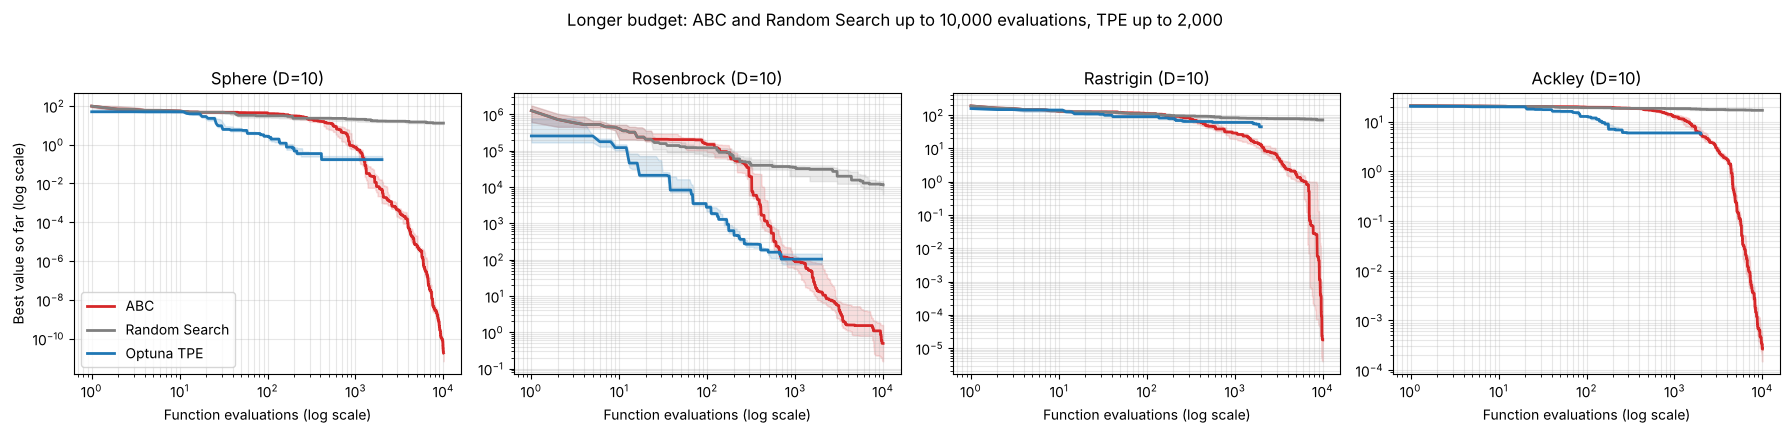

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, fname in zip(axes, FUNCTIONS):
    for method in METHODS:
        c = long_curves[fname, method]
        xs = np.arange(1, c.shape[1] + 1)
        med = np.median(c, axis=0)
        q1, q3 = np.percentile(c, [25, 75], axis=0)
        ax.plot(xs, med, label=method, color=COLORS[method], lw=2)
        ax.fill_between(xs, q1, q3, color=COLORS[method], alpha=0.15)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(f"{fname} (D={D})")
    ax.set_xlabel("Function evaluations (log scale)")
    ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("Best value so far (log scale)")
axes[0].legend()
fig.suptitle("Longer budget: ABC and Random Search up to 10,000 evaluations, TPE up to 2,000", y=1.02)
fig.tight_layout()
fig.savefig("benchmark_functions_long.png", dpi=150, bbox_inches="tight")
plt.show()

### Optimizer overhead

How long does each method spend *deciding where to look next*? The objective here is a trivial Sphere function, so the time measured is almost entirely the optimizer's own computation.

In [8]:
def overhead(method, n, seed=0):
    f, lo, hi = FUNCTIONS["Sphere"]
    t0 = time.perf_counter()
    if method == "ABC":
        run_abc_long(f, lo, hi, seed, n)
    elif method == "Random Search":
        run_random_long(f, lo, hi, seed, n)
    else:
        run_tpe_long(f, lo, hi, seed, n)
    return time.perf_counter() - t0

sizes = [250, 500, 1000, 2000]
over = pd.DataFrame({m: [overhead(m, n) for n in sizes] for m in METHODS},
                    index=pd.Index(sizes, name="evaluations"))
print("Wall-clock seconds for one run on Sphere (D=10)\n")
print(over.map(lambda v: f"{v:.3f}").to_markdown())

Wall-clock seconds for one run on Sphere (D=10)

|   evaluations |   ABC |   Random Search |   Optuna TPE |
|--------------:|------:|----------------:|-------------:|
|           250 | 0.005 |           0.001 |        1.021 |
|           500 | 0.01  |           0.001 |        2.917 |
|          1000 | 0.022 |           0.002 |        8.301 |
|          2000 | 0.043 |           0.005 |       27.765 |


## Part 2: Hyperparameter tuning

Two tasks with different kinds of search spaces:

| Task | Model | Search space |
|---|---|---|
| **Digits** (1,797 images, 10 classes) | `SVC` | `C` ∈ [1e-3, 1e3] (log), `gamma` ∈ [1e-5, 1e-1] (log), `kernel` ∈ {rbf, sigmoid} |
| **Breast Cancer** (569 samples, 2 classes) | `HistGradientBoostingClassifier` | `learning_rate` ∈ [1e-3, 0.5] (log), `max_iter` ∈ [20, 300], `max_leaf_nodes` ∈ [4, 64], `min_samples_leaf` ∈ [2, 60], `l2_regularization` ∈ [1e-6, 10] (log) |

**Protocol**

- 80/20 stratified train/test split (fixed). Tuning only ever sees the training part.
- Each candidate is scored with the **same** 3-fold stratified CV on the training set (metric: accuracy).
- **50 candidates per run**, 5 seeds per method.
- The best configuration is refit on the full training set and evaluated **once** on the untouched test set.

In [9]:
from sklearn.datasets import load_breast_cancer, load_digits
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

N_CANDIDATES = 50
HPO_SEEDS = range(5)
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)

# One search space per task, written once and translated for each library.
# (name, type, low, high, log)  or  (name, "categorical", choices)
TASKS = {
    "Digits / SVC": dict(
        data=load_digits(return_X_y=True),
        model=make_pipeline(StandardScaler(), SVC()),
        prefix="svc__",
        space=[("C", "float", 1e-3, 1e3, True),
               ("gamma", "float", 1e-5, 1e-1, True),
               ("kernel", "categorical", ["rbf", "sigmoid"])],
    ),
    "Breast Cancer / HistGB": dict(
        data=load_breast_cancer(return_X_y=True),
        model=HistGradientBoostingClassifier(random_state=0),
        prefix="",
        space=[("learning_rate", "float", 1e-3, 0.5, True),
               ("max_iter", "int", 20, 300, False),
               ("max_leaf_nodes", "int", 4, 64, False),
               ("min_samples_leaf", "int", 2, 60, False),
               ("l2_regularization", "float", 1e-6, 10.0, True)],
    ),
}

def to_abc(space, prefix):
    out = {}
    for s in space:
        if s[1] == "categorical":
            out[prefix + s[0]] = {"type": "categorical", "choices": s[2]}
        else:
            out[prefix + s[0]] = {"type": s[1], "range": (s[2], s[3]), "log": s[4]}
    return out

def to_sklearn(space, prefix):
    out = {}
    for s in space:
        if s[1] == "categorical":
            out[prefix + s[0]] = s[2]
        elif s[1] == "int":
            out[prefix + s[0]] = randint(s[2], s[3] + 1)
        elif s[4]:
            out[prefix + s[0]] = loguniform(s[2], s[3])
        else:
            out[prefix + s[0]] = uniform(s[2], s[3] - s[2])
    return out

def suggest(trial, space, prefix):
    params = {}
    for s in space:
        name = prefix + s[0]
        if s[1] == "categorical":
            params[name] = trial.suggest_categorical(name, s[2])
        elif s[1] == "int":
            params[name] = trial.suggest_int(name, s[2], s[3])
        else:
            params[name] = trial.suggest_float(name, s[2], s[3], log=s[4])
    return params

In [10]:
def tune(task, method, seed, X_tr, y_tr):
    model, space, prefix = task["model"], task["space"], task["prefix"]
    if method == "ABC":
        s = ABCSearchCV(model, to_abc(space, prefix), cv=CV, scoring="accuracy",
                        pop_size=10, max_evals=N_CANDIDATES, random_state=seed,
                        refit=False).fit(X_tr, y_tr)
        return s.best_params_, [r["score"] for r in s.results_]
    if method == "Random Search":
        s = RandomizedSearchCV(model, to_sklearn(space, prefix), n_iter=N_CANDIDATES,
                               cv=CV, scoring="accuracy", random_state=seed,
                               refit=False).fit(X_tr, y_tr)
        return s.best_params_, list(s.cv_results_["mean_test_score"])
    # Optuna TPE
    def objective(trial):
        model_t = sklearn.base.clone(model).set_params(**suggest(trial, space, prefix))
        return cross_val_score(model_t, X_tr, y_tr, cv=CV, scoring="accuracy").mean()
    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=N_CANDIDATES)
    return study.best_params, [t.value for t in study.trials]

hpo_rows, hpo_curves = [], {}
for tname, task in TASKS.items():
    X, y = task["data"]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
    for method in METHODS:
        traces = []
        for seed in HPO_SEEDS:
            t0 = time.perf_counter()
            params, scores = tune(task, method, seed, X_tr, y_tr)
            elapsed = time.perf_counter() - t0
            final_model = sklearn.base.clone(task["model"]).set_params(**params).fit(X_tr, y_tr)
            traces.append(np.maximum.accumulate(np.nan_to_num(scores, nan=0.0)))
            hpo_rows.append({"Task": tname, "Method": method, "Seed": seed,
                             "CV accuracy": max(scores), "Test accuracy": final_model.score(X_te, y_te),
                             "seconds": elapsed})
        hpo_curves[tname, method] = np.array(traces)
    print(f"{tname} done")

hpo = pd.DataFrame(hpo_rows)

Digits / SVC done


Breast Cancer / HistGB done


In [11]:
summary = (hpo.groupby(["Task", "Method"])[["CV accuracy", "Test accuracy", "seconds"]]
              .agg(["mean", "std"]))
fmt = pd.DataFrame(index=summary.index)
for col in ["CV accuracy", "Test accuracy"]:
    fmt[col] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(summary[col, "mean"], summary[col, "std"])]
fmt["time / run (s)"] = [f"{m:.1f}" for m in summary["seconds", "mean"]]
fmt = fmt.reindex([(t, m) for t in TASKS for m in METHODS])
print(f"Mean ± std over {len(HPO_SEEDS)} seeds, {N_CANDIDATES} candidates each\n")
print(fmt.to_markdown())

Mean ± std over 5 seeds, 50 candidates each

|                                             | CV accuracy     | Test accuracy   |   time / run (s) |
|:--------------------------------------------|:----------------|:----------------|-----------------:|
| ('Digits / SVC', 'ABC')                     | 0.9798 ± 0.0007 | 0.9811 ± 0.0030 |             10   |
| ('Digits / SVC', 'Random Search')           | 0.9809 ± 0.0017 | 0.9833 ± 0.0020 |              9.6 |
| ('Digits / SVC', 'Optuna TPE')              | 0.9808 ± 0.0011 | 0.9839 ± 0.0012 |              8   |
| ('Breast Cancer / HistGB', 'ABC')           | 0.9627 ± 0.0027 | 0.9579 ± 0.0073 |             19.8 |
| ('Breast Cancer / HistGB', 'Random Search') | 0.9644 ± 0.0018 | 0.9632 ± 0.0039 |             18   |
| ('Breast Cancer / HistGB', 'Optuna TPE')    | 0.9710 ± 0.0029 | 0.9614 ± 0.0118 |             16.1 |


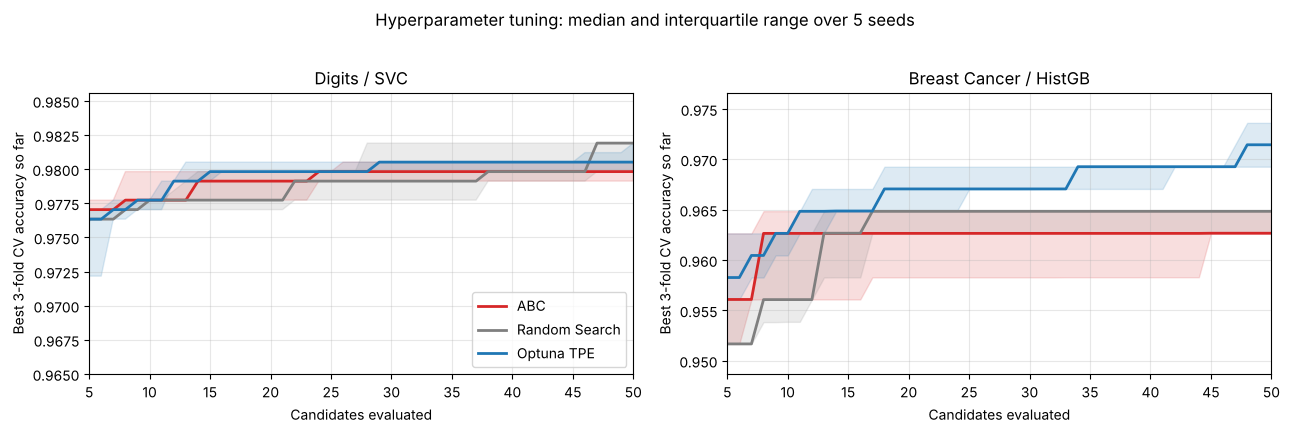

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(1, N_CANDIDATES + 1)
for ax, tname in zip(axes, TASKS):
    for method in METHODS:
        c = hpo_curves[tname, method]
        med = np.median(c, axis=0)
        q1, q3 = np.percentile(c, [25, 75], axis=0)
        ax.plot(x, med, label=method, color=COLORS[method], lw=2)
        ax.fill_between(x, q1, q3, color=COLORS[method], alpha=0.15)
    ax.set_title(tname)
    ax.set_xlabel("Candidates evaluated")
    ax.set_ylabel("Best 3-fold CV accuracy so far")
    ax.grid(alpha=0.3)
    vals = np.concatenate([hpo_curves[tname, m][:, 4:].ravel() for m in METHODS])
    ax.set_ylim(np.percentile(vals, 2) - 0.003, min(1.0, vals.max() + 0.003))
    ax.set_xlim(5, N_CANDIDATES)
axes[0].legend(loc="lower right")
fig.suptitle("Hyperparameter tuning: median and interquartile range over 5 seeds", y=1.02)
fig.tight_layout()
fig.savefig("benchmark_hpo.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
func_results.to_csv("results_functions.csv", index=False)
over.to_csv("results_overhead.csv")
hpo.to_csv("results_hpo.csv", index=False)

## Discussion

**1. Small budgets favour TPE.** With 1,000 evaluations TPE reaches the best value on Sphere, Rosenbrock and Ackley. TPE builds a probabilistic model of where good points lie and spends every evaluation carefully, which is exactly what a short budget rewards. ABC is clearly better than Random Search everywhere and is the best of the three on **Rastrigin** (26.3 vs 59.7 for TPE), the most multimodal function, where TPE stalls in a local basin.

**2. With a larger budget ABC converges, TPE stalls.** Given 10,000 evaluations ABC reaches essentially the global optimum on all four functions (Sphere 5e-11, Rastrigin 0.10, Ackley 0.0004, Rosenbrock 0.99). TPE's curves are flat from roughly 500 evaluations onwards, and at 2,000 evaluations it is still at 47.3 on Rastrigin and 5.8 on Ackley. Random Search barely improves at all in 10 dimensions.

**3. ABC's own overhead is negligible.** ABC spends about 0.04 s deciding where to look over 2,000 evaluations, versus about 28 s for TPE (roughly 650× more), and TPE's cost grows faster than linearly with the number of trials. When the objective itself is cheap (simulations, analytic functions, fast models), this decides which method is usable.

**4. Hyperparameter tuning with 50 candidates: no win for ABC.** On Digits/SVC all three methods end within 0.1 percentage points of CV accuracy. On Breast Cancer/HistGB, TPE finds the best CV accuracy (97.1% vs 96.4% Random and 96.3% ABC). On the held-out test set the differences shrink to within one standard deviation; the test set has only 114 samples, so one sample is 0.9 points. With `pop_size=10` and 50 candidates, ABC completes only about two employed/onlooker cycles, so it has very little room to exploit what it found.

### When to use which

| Situation | Recommendation |
|---|---|
| Expensive objective, budget of tens to a few hundred evaluations (typical deep-learning HPO) | **Optuna TPE** |
| Cheap objective, thousands of evaluations available | **ABC** |
| Rugged, highly multimodal landscape | **ABC** |
| Need a scikit-learn drop-in with no extra dependencies | **ABC** (`ABCSearchCV`) or Random Search |

### Limitations of this benchmark

- One dimension (D = 10), four test functions and two tuning tasks; results may differ in other settings.
- Every method uses its default settings; none was tuned for these problems.
- TPE was stopped at 2,000 evaluations (3 seeds) in the long-budget run because of its runtime.
- Tuning results use 5 seeds and a single train/test split, so small differences are not statistically meaningful.
